## Setup

In [1]:
# If anything is missing, uncomment:
# %pip install pandas numpy scipy statsmodels matplotlib
# %pip install "xlrd>=2.0.1"


In [2]:
from __future__ import annotations

from dataclasses import dataclass
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
from scipy import stats, signal
from scipy.optimize import minimize_scalar
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.tsa.stattools import adfuller, kpss, grangercausalitytests, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

%matplotlib inline
import matplotlib.pyplot as plt
from IPython.display import display

plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.bbox"] = "tight"
pd.set_option("display.float_format", lambda x: f"{x:.6f}")


## Config — set Paths

In [3]:
import os

#  project root 
THESIS_DATA_ROOT = Path(os.environ.get("THESIS_DATA_ROOT", "./thesis_data")).resolve()
ROOT = THESIS_DATA_ROOT
ROOT.mkdir(parents=True, exist_ok=True)


INDICES_PATH = THESIS_DATA_ROOT / "Phase 3" / "full_period_US_phase3_20260602_014115" / "US_full_period_phase3_daily_indices.csv"
SUMMARY_PATH = THESIS_DATA_ROOT / "Phase 3" / "full_period_US_phase3_20260602_014115" / "US_full_period_phase3_summary.csv"        

## Load data

### Index 

In [4]:
import os
from pathlib import Path

#  project root 
THESIS_DATA_ROOT = Path(os.environ.get("THESIS_DATA_ROOT", "./thesis_data")).resolve()
ROOT = THESIS_DATA_ROOT
ROOT.mkdir(parents=True, exist_ok=True)

#  Submission Ready root 
SUBMISSION_ROOT = Path(os.environ.get(
    "SUBMISSION_ROOT", str(Path.home() / "Desktop" / "PCRA Index Thesis")
)).resolve()


INDICES_PATH = (SUBMISSION_ROOT / "Actual Run Data" / "Phase 3 - Index"
                 / "US_full_period_phase3_daily_indices.csv")
SUMMARY_PATH = (SUBMISSION_ROOT / "Actual Run Data" / "Phase 3 - Index"
                 / "US_full_period_phase3_summary.csv")


STAGE_A_DIRS = [
    SUBMISSION_ROOT / "Actual Run Data" / "Phase 1 - Articles Kept vs Rejected"
    / "Stage A" / "Full Data",
]

StageB_PATH = (SUBMISSION_ROOT / "Actual Run Data" / "Phase 1 - Articles Kept vs Rejected")


figdir = SUBMISSION_ROOT / "Visuals" / "Predeterminedness"
figdir.mkdir(parents=True, exist_ok=True)

print(f"SUBMISSION_ROOT: {SUBMISSION_ROOT}  {'✓' if SUBMISSION_ROOT.exists() else '✗ NOT FOUND'}")
print(f"  Indices: {INDICES_PATH}  {'✓' if INDICES_PATH.exists() else '✗ NOT FOUND'}")
print(f"  Summary: {SUMMARY_PATH}  {'✓' if SUMMARY_PATH.exists() else '✗ NOT FOUND'}")
print(f"  Figures: {figdir}  {'✓ created/exists' if figdir.exists() else '✗ FAILED'}")

SUBMISSION_ROOT: /Users/adam/Desktop/PCRA Index Thesis  ✓
  Indices: /Users/adam/Desktop/PCRA Index Thesis/Actual Run Data/Phase 3 - Index/US_full_period_phase3_daily_indices.csv  ✓
  Summary: /Users/adam/Desktop/PCRA Index Thesis/Actual Run Data/Phase 3 - Index/US_full_period_phase3_summary.csv  ✓
  Figures: /Users/adam/Desktop/PCRA Index Thesis/Visuals/Predeterminedness  ✓ created/exists


In [5]:
df = pd.read_csv(INDICES_PATH)
df["date"] = pd.to_datetime(df["date"])
if "DSP" in df.columns:
    df = df.rename(columns={"DSP": "CSP"})
print(f"✓ df loaded: {len(df):,} rows, columns: {list(df.columns)}")

✓ df loaded: 4,697 rows, columns: ['date', 'country', 'S_daily_raw', 'S_daily', 'SSI', 'CSP']


### Benchmark Index Paths (EM-DAt, EPU, CPU)

In [6]:
from pathlib import Path

EMDAT_DIR = SUBMISSION_ROOT / "Financial Data" / "Disaster"
EPU_DIR   = SUBMISSION_ROOT / "Financial Data" / "Other Indices"

# Country name --> ISO code for EM-DAT filenames
EMDAT_FILES = {
    "US": EMDAT_DIR / "EMDAT_US.xlsx",
}

# Verify expected paths exist
print(f"SUBMISSION_ROOT: {SUBMISSION_ROOT}  {'✓' if SUBMISSION_ROOT.exists() else '✗ NOT FOUND'}")
print(f"  EM-DAT:    {EMDAT_DIR}  {'✓' if EMDAT_DIR.exists() else '✗ NOT FOUND'}")
print(f"  Other Idx: {EPU_DIR}  {'✓' if EPU_DIR.exists() else '✗ NOT FOUND'}")

SUBMISSION_ROOT: /Users/adam/Desktop/PCRA Index Thesis  ✓
  EM-DAT:    /Users/adam/Desktop/PCRA Index Thesis/Financial Data/Disaster  ✓
  Other Idx: /Users/adam/Desktop/PCRA Index Thesis/Financial Data/Other Indices  ✓


In [7]:
#  Path 


EPU_PATH = EPU_DIR / "All_Daily_Policy_Data.csv"

print(f"  EPU path: {EPU_PATH}")
print(f"  Exists  : {'✓' if EPU_PATH.exists() else '✗ NOT FOUND'}")

if not EPU_PATH.exists():
    raise FileNotFoundError(
        f"EPU file not found at {EPU_PATH}\n"
        f"Files currently in Other Indices folder:\n"
        + "\n".join(f"  {f.name}" for f in EPU_DIR.iterdir())
        if EPU_DIR.exists() else
        f"EPU file not found at {EPU_PATH}\nOther Indices folder itself doesn't exist: {EPU_DIR}"
    )


epu_raw = pd.read_csv(EPU_PATH)
print(f"\n✓ Loaded EPU: {len(epu_raw):,} rows")
print(f"  Columns: {list(epu_raw.columns)}")

#  Build date from year  month  day 

epu_raw["date"] = pd.to_datetime({
    "year":  epu_raw["year"].astype(int),
    "month": epu_raw["month"].astype(int),
    "day":   epu_raw["day"].astype(int),
}, errors="coerce")

#  Clean & filter 

epu_df = epu_raw[["date", "daily_policy_index"]].copy()
epu_df.columns = ["date", "epu"]
epu_df["epu"] = pd.to_numeric(epu_df["epu"], errors="coerce")
epu_df = epu_df.dropna(subset=["date", "epu"])

epu_df = epu_df[
    (epu_df["date"] >= "2008-01-01") &
    (epu_df["date"] <= "2025-12-31")
].sort_values("date").reset_index(drop=True)

#  Summary 

print(f"\n✓ epu_df ready")
print(f"  Observations : {len(epu_df):,}")
print(f"  Date range   : {epu_df['date'].min().date()} "
      f"→ {epu_df['date'].max().date()}")
print(f"  Mean EPU     : {epu_df['epu'].mean():.2f}")
print(f"  Max EPU      : {epu_df['epu'].max():.2f}")

display(epu_df.head())

  EPU path: /Users/adam/Desktop/PCRA Index Thesis/Financial Data/Other Indices/All_Daily_Policy_Data.csv
  Exists  : ✓

✓ Loaded EPU: 15,125 rows
  Columns: ['day', 'month', 'year', 'daily_policy_index']

✓ epu_df ready
  Observations : 6,575
  Date range   : 2008-01-01 → 2025-12-31
  Mean EPU     : 144.66
  Max EPU      : 1026.38


,date,epu
0,2008-01-01,232.870000
1,2008-01-02,83.140000
2,2008-01-03,189.340000
3,2008-01-04,103.240000
4,2008-01-05,281.750000


In [8]:
import pandas as pd
import numpy as np
from pathlib import Path

#  EM-DAT file 
EMDAT_FILES = {
    "US": EMDAT_DIR / "EMDAT_US.xlsx",
}

print(f"  EM-DAT US path: {EMDAT_FILES['US']}")
print(f"  Exists        : {'✓' if EMDAT_FILES['US'].exists() else '✗ NOT FOUND'}")

if not EMDAT_FILES["US"].exists():
    raise FileNotFoundError(
        f"EM-DAT file not found at {EMDAT_FILES['US']}\n"
        f"Files currently in EM-DAT folder:\n"
        + ("\n".join(f"  {f.name}" for f in EMDAT_DIR.iterdir())
           if EMDAT_DIR.exists() else f"  (folder itself doesn't exist: {EMDAT_DIR})")
    )

#  Load US EM-DAT file 

emdat_raw = pd.read_excel(EMDAT_FILES["US"])
print(f"\n✓ Loaded EM-DAT US: {len(emdat_raw):,} rows")
print(f"  Columns: {list(emdat_raw.columns)}")

#  Identify date column 

if "Start Year" in emdat_raw.columns:
    emdat_raw["event_date"] = pd.to_datetime({
        "year":  emdat_raw["Start Year"].fillna(0).astype(int),
        "month": emdat_raw["Start Month"].fillna(1).astype(int),
        "day":   emdat_raw["Start Day"].fillna(1).astype(int),
    }, errors="coerce")
elif "Disaster Date" in emdat_raw.columns:
    emdat_raw["event_date"] = pd.to_datetime(
        emdat_raw["Disaster Date"], errors="coerce")
elif "Event Date" in emdat_raw.columns:
    emdat_raw["event_date"] = pd.to_datetime(
        emdat_raw["Event Date"], errors="coerce")
else:
    raise RuntimeError(
        f"Cannot find a date column in EM-DAT. "
        f"Available columns: {list(emdat_raw.columns)}")

#  Filter to sample period & drop undated rows 

emdat_us = emdat_raw.dropna(subset=["event_date"]).copy()
emdat_us = emdat_us[
    (emdat_us["event_date"] >= "2008-01-01") &
    (emdat_us["event_date"] <= "2025-12-31")
].reset_index(drop=True)

print(f"  After date filter (2008–2025): {len(emdat_us):,} events")

# ^ Build emdat_dates

emdat_dates = pd.to_datetime(
    emdat_us["event_date"].dropna().values,
    errors="coerce"
)
emdat_dates = emdat_dates[~pd.isnull(emdat_dates)]

print(f"  emdat_dates ready : {len(emdat_dates):,} dates")

#  Build EMDAT_EVENTS 
_desc_col = next(
    (c for c in ["Disaster Type", "Event Name", "Disaster Subtype", "Type"]
     if c in emdat_us.columns), None)

_type_col = next(
    (c for c in ["Disaster Subtype", "Disaster Type", "Event Type"]
     if c in emdat_us.columns), None)

_chronic_terms = [
    "drought", "sea level", "heat stress", "extreme temperature",
    "cold wave", "heat wave", "wildfire", "land fire"
]

def _classify_type(row):
    if _type_col is None:
        return "acute"
    val = str(row[_type_col]).lower()
    return "chronic" if any(t in val for t in _chronic_terms) else "acute"

emdat_us["etype"] = emdat_us.apply(_classify_type, axis=1)

if _desc_col:
    EMDAT_EVENTS = list(zip(
        emdat_us["event_date"].dt.strftime("%Y-%m-%d"),
        emdat_us[_desc_col].fillna("Unknown"),
        emdat_us["etype"]
    ))
else:
    EMDAT_EVENTS = list(zip(
        emdat_us["event_date"].dt.strftime("%Y-%m-%d"),
        ["Event"] * len(emdat_us),
        emdat_us["etype"]
    ))

print(f"  EMDAT_EVENTS ready: {len(EMDAT_EVENTS):,} entries "
      f"({emdat_us['etype'].eq('acute').sum():,} acute, "
      f"{emdat_us['etype'].eq('chronic').sum():,} chronic)")

  EM-DAT US path: /Users/adam/Desktop/PCRA Index Thesis/Financial Data/Disaster/EMDAT_US.xlsx
  Exists        : ✓

✓ Loaded EM-DAT US: 417 rows
  Columns: ['DisNo.', 'Historic', 'Classification Key', 'Disaster Group', 'Disaster Subgroup', 'Disaster Type', 'Disaster Subtype', 'External IDs', 'Event Name', 'ISO', 'Country', 'Subregion', 'Region', 'Location', 'Origin', 'Associated Types', 'OFDA/BHA Response', 'Appeal', 'Declaration', "AID Contribution ('000 US$)", 'Magnitude', 'Magnitude Scale', 'Latitude', 'Longitude', 'River Basin', 'Start Year', 'Start Month', 'Start Day', 'End Year', 'End Month', 'End Day', 'Total Deaths', 'No. Injured', 'No. Affected', 'No. Homeless', 'Total Affected', "Reconstruction Costs ('000 US$)", "Reconstruction Costs, Adjusted ('000 US$)", "Insured Damage ('000 US$)", "Insured Damage, Adjusted ('000 US$)", "Total Damage ('000 US$)", "Total Damage, Adjusted ('000 US$)", 'CPI', 'Admin Units', 'GADM Admin Units', 'Entry Date', 'Last Update']
  After date filter 

In [9]:
#  Path 
CPU_PATH = EPU_DIR / "cpu_pu.xlsx"
print(f"  CPU path: {CPU_PATH}")
print(f"  Exists  : {'✓' if CPU_PATH.exists() else '✗ NOT FOUND'}")

if not CPU_PATH.exists():
    raise FileNotFoundError(
        f"CPU file not found at {CPU_PATH}\n"
        f"Files currently in Other Indices folder:\n"
        + ("\n".join(f"  {f.name}" for f in EPU_DIR.iterdir())
           if EPU_DIR.exists() else f"  (folder itself doesn't exist: {EPU_DIR})"))

#  Inspect sheets 
xl = pd.ExcelFile(CPU_PATH)
print(f"\n  Sheets available: {xl.sheet_names}")

#  Load sheet 2 data
cpu_raw = pd.read_excel(
    CPU_PATH,
    sheet_name=xl.sheet_names[1],
    dtype={"date": str})

print(f"\n✓ Loaded CPU from sheet: '{xl.sheet_names[1]}'")
print(f"  Rows              : {len(cpu_raw):,}")
print(f"  Columns           : {list(cpu_raw.columns)}")
print(f"  Date sample (raw) : {cpu_raw['date'].head(5).tolist()}")
display(cpu_raw.head(5))

#  Build date 
cpu_raw["date"] = pd.to_datetime(
    cpu_raw["date"].astype(str).str.strip().str.replace("M", "-") + "-01",
    format="%Y-%m-%d",
    errors="coerce"
)
print(f"\n  Date sample (parsed): {cpu_raw['date'].dropna().head(3).tolist()}")

#  Select index columns 
cpu_value_cols = [c for c in cpu_raw.columns if c not in
                  ["year", "month", "day", "date"]]
print(f"  CPU value columns found: {cpu_value_cols}")

cpu_df = cpu_raw[["date"] + cpu_value_cols].copy()

#  Standardise column names 
rename_map = {}
for col in cpu_value_cols:
    col_lower = col.lower()
    if "narrow" in col_lower and "news" not in col_lower:
        rename_map[col] = "cpu_index_narrow"
    elif "broad" in col_lower and "news" not in col_lower:
        rename_map[col] = "cpu_index_broad"
    elif "gavriilidis" in col_lower or col_lower in ["cpu", "cpu_index"]:
        rename_map[col] = "cpu_index_gavriilidis"
    elif "news" in col_lower and "narrow" in col_lower:
        rename_map[col] = "cpnews_index_narrow"
    elif "news" in col_lower and "broad" in col_lower:
        rename_map[col] = "cpnews_index_broad"
    elif "sent" in col_lower:
        rename_map[col] = "cpsent_index"
    elif "instrument" in col_lower:
        rename_map[col] = "cpu_instrument"
    elif "shock" in col_lower:
        rename_map[col] = "cpu_shock"

if rename_map:
    cpu_df = cpu_df.rename(columns=rename_map)
    print(f"  Renamed columns: {rename_map}")

#  Convert value columns to numeric 
for col in cpu_df.columns:
    if col != "date":
        cpu_df[col] = pd.to_numeric(cpu_df[col], errors="coerce")

cpu_df = (cpu_df
    .dropna(subset=["date"])
    .loc[lambda d: (d["date"] >= "2008-01-01") & (d["date"] <= "2025-12-31")]
    .sort_values("date")
    .reset_index(drop=True))

#  Summary 
print(f"\n✓ cpu_df ready")
print(f"  Observations : {len(cpu_df):,}")
print(f"  Date range   : {cpu_df['date'].min().date()} "
      f"→ {cpu_df['date'].max().date()}")
print(f"  Columns      : {list(cpu_df.columns)}")
for col in cpu_df.columns:
    if col != "date":
        non_null = cpu_df[col].dropna()
        if len(non_null) > 0:
            print(f"  {col:<30s} mean={non_null.mean():.2f}  "
                  f"max={non_null.max():.2f}  "
                  f"n={len(non_null):,}")
        else:
            print(f"  {col:<30s} all NaN")
display(cpu_df.head())

  CPU path: /Users/adam/Desktop/PCRA Index Thesis/Financial Data/Other Indices/cpu_pu.xlsx
  Exists  : ✓

  Sheets available: ['readme', 'data']

✓ Loaded CPU from sheet: 'data'
  Rows              : 492
  Columns           : ['date', 'cpu_index_narrow', 'cpu_index_broad', 'cpu_index_gavriilidis', 'cpnews_index_narrow', 'cpnews_index_broad', 'cpsent_index', 'cpu_instrument', 'cpu_shock']
  Date sample (raw) : ['1985M01', '1985M02', '1985M03', '1985M04', '1985M05']


,date,cpu_index_narrow,cpu_index_broad,cpu_index_gavriilidis,cpnews_index_narrow,cpnews_index_broad,cpsent_index,cpu_instrument,cpu_shock
0,1985M01,35.469868,67.558322,NaN,52.560527,54.654046,146.698243,NaN,NaN
1,1985M02,12.957033,16.960149,NaN,51.736757,51.679215,98.249098,NaN,NaN
2,1985M03,35.618421,61.085415,NaN,60.033463,58.400578,229.254864,NaN,NaN
3,1985M04,59.485346,48.462095,NaN,47.960487,51.492845,178.405419,NaN,NaN
4,1985M05,26.375457,34.621114,NaN,46.887293,49.883908,90.879046,NaN,NaN



  Date sample (parsed): [Timestamp('1985-01-01 00:00:00'), Timestamp('1985-02-01 00:00:00'), Timestamp('1985-03-01 00:00:00')]
  CPU value columns found: ['cpu_index_narrow', 'cpu_index_broad', 'cpu_index_gavriilidis', 'cpnews_index_narrow', 'cpnews_index_broad', 'cpsent_index', 'cpu_instrument', 'cpu_shock']
  Renamed columns: {'cpu_index_narrow': 'cpu_index_narrow', 'cpu_index_broad': 'cpu_index_broad', 'cpu_index_gavriilidis': 'cpu_index_gavriilidis', 'cpnews_index_narrow': 'cpnews_index_narrow', 'cpnews_index_broad': 'cpnews_index_broad', 'cpsent_index': 'cpsent_index', 'cpu_instrument': 'cpu_instrument', 'cpu_shock': 'cpu_shock'}

✓ cpu_df ready
  Observations : 216
  Date range   : 2008-01-01 → 2025-12-01
  Columns      : ['date', 'cpu_index_narrow', 'cpu_index_broad', 'cpu_index_gavriilidis', 'cpnews_index_narrow', 'cpnews_index_broad', 'cpsent_index', 'cpu_instrument', 'cpu_shock']
  cpu_index_narrow               mean=258.70  max=916.28  n=216
  cpu_index_broad               

,date,cpu_index_narrow,cpu_index_broad,cpu_index_gavriilidis,cpnews_index_narrow,cpnews_index_broad,cpsent_index,cpu_instrument,cpu_shock
0,2008-01-01,165.633687,139.253340,94.648509,142.021777,116.369936,95.839287,0.000000,0.325613
1,2008-02-01,143.749401,122.719308,96.943516,115.694766,104.871164,108.800735,0.000000,0.219075
2,2008-03-01,111.876447,75.812874,55.128163,129.749332,106.656863,168.340079,0.000000,-0.571754
3,2008-04-01,143.723709,125.556904,93.901780,149.634044,129.335019,183.769227,0.000000,0.479395
4,2008-05-01,153.042190,127.720523,85.667217,140.454251,128.767182,130.668079,-0.274189,0.681724


### Treasury Yield Data

In [10]:
# Check INDICES_PATH
try:
    INDICES_PATH
    print(f"✓ INDICES_PATH: {INDICES_PATH}")
except NameError:
    INDICES_PATH = ROOT / "indices" / "US_daily_index.csv"
    print(f"  INDICES_PATH set to: {INDICES_PATH}")

#  Yield configuration
SOVEREIGN_DIR = SUBMISSION_ROOT / "Financial Data" / "Sovereign"

if not SOVEREIGN_DIR.exists():
    raise FileNotFoundError(
        f"'Sovereign' folder not found at {SOVEREIGN_DIR}. "
        f"Contents of Financial Data:\n"
        + "\n".join(f"  {p.name}" for p in (SUBMISSION_ROOT / "Financial Data").iterdir())
    )

YIELDS_DIR    = SOVEREIGN_DIR
YIELD_TICKERS = {"US": "TY"}

print(f"✓ YIELDS_DIR: {YIELDS_DIR}")
print(f"✓ YIELD_TICKERS: {YIELD_TICKERS}")

#  ACM term premium and MOVE index — confirmed filenames 
ACM_PATH  = SOVEREIGN_DIR / "ACMTermPremium.xls"
MOVE_PATH = SOVEREIGN_DIR / "MOVE Index.csv"

for _label, _path in [("ACM term premium", ACM_PATH), ("MOVE index", MOVE_PATH)]:
    print(f"{_label:<18s}: {_path}  {'✓' if _path.exists() else '✗ NOT FOUND'}")

if not ACM_PATH.exists() or not MOVE_PATH.exists():
    raise FileNotFoundError(
        f"One or more files not found. Actual contents of {SOVEREIGN_DIR}:\n"
        + "\n".join(f"  {p.name}" for p in SOVEREIGN_DIR.iterdir())
    )

✓ INDICES_PATH: /Users/adam/Desktop/PCRA Index Thesis/Actual Run Data/Phase 3 - Index/US_full_period_phase3_daily_indices.csv
✓ YIELDS_DIR: /Users/adam/Desktop/PCRA Index Thesis/Financial Data/Sovereign
✓ YIELD_TICKERS: {'US': 'TY'}
ACM term premium  : /Users/adam/Desktop/PCRA Index Thesis/Financial Data/Sovereign/ACMTermPremium.xls  ✓
MOVE index        : /Users/adam/Desktop/PCRA Index Thesis/Financial Data/Sovereign/MOVE Index.csv  ✓


In [11]:
if "country" in df.columns:
    country = df["country"].dropna().iloc[0]
else:
    country = "US"

ticker     = YIELD_TICKERS[country]
yield_file = YIELDS_DIR / f"{ticker}.csv"

print(f"Country    : {country}")
print(f"Ticker     : {ticker}")
print(f"File       : {yield_file}")
print(f"Exists     : {'✓' if yield_file.exists() else '✗ NOT FOUND'}")

if not yield_file.exists():
    raise FileNotFoundError(f"Yield file not found: {yield_file}")

Country    : US
Ticker     : TY
File       : /Users/adam/Desktop/PCRA Index Thesis/Financial Data/Sovereign/TY.csv
Exists     : ✓


In [12]:
yield_df = pd.read_csv(yield_file)
print(f"\nColumns : {yield_df.columns.tolist()}")
display(yield_df.head(3))


Columns : ['Date', 'Time', 'Open', 'High', 'Low', 'Close', 'Volume', 'Tick Count']


,Date,Time,Open,High,Low,Close,Volume,Tick Count
0,01/03/1983,08:01,30.779785,30.791172,30.779785,30.791172,0,2
1,01/03/1983,08:02,30.779785,30.813947,30.768398,30.813947,0,6
2,01/03/1983,08:03,30.802559,30.813947,30.802559,30.813947,0,2


### Move Index

In [13]:
move_df = pd.read_csv(MOVE_PATH)
print(f"MOVE columns: {list(move_df.columns)}")
display(move_df.head(3))

MOVE columns: ['index', 'us']


,index,us
0,1980-01-01T00:00:00.000Z,NaN
1,1980-01-02T00:00:00.000Z,NaN
2,1980-01-03T00:00:00.000Z,NaN


## Helpers

In [14]:
@dataclass
class CheckResult:
    name: str
    passed: bool | None
    value: str
    note: str = ""

    def show(self):
        if self.passed is None:
            tag = "[ INFO ]"
        elif self.passed:
            tag = "[ PASS ]"
        else:
            tag = "[ FAIL ]"
        print(f"{tag}  {self.name:55s}  {self.value}")
        if self.note:
            print(f"          note: {self.note}")


def ewma(x: np.ndarray, lam: float, init: float | None = None) -> np.ndarray:
    #SSI_t = lam*SSI_{t-1} + (1-lam)*S_t (proposal Phase 3)
    out = np.empty_like(x, dtype=float)
    out[0] = init if init is not None else x[0]
    for i in range(1, len(x)):
        out[i] = lam * out[i - 1] + (1.0 - lam) * x[i]
    return out


def kpss_safe(series, regression="c"):
    import warnings
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        stat, p, *_ = kpss(series, regression=regression, nlags="auto")
    return stat, p


def hl_to_lambda(hl: int) -> float:
    #Half-life (business days) -> EWMA lambda. lambda^h = 1/2
    return float(2.0 ** (-1.0 / hl))


def distance_correlation(x: np.ndarray, y: np.ndarray) -> float:
    #Szekely-Rizzo-Bakirov distance correlation. O(n^2)
    x = np.asarray(x, dtype=float).reshape(-1)
    y = np.asarray(y, dtype=float).reshape(-1)
    a = np.abs(x[:, None] - x[None, :])
    b = np.abs(y[:, None] - y[None, :])
    A = a - a.mean(0) - a.mean(1)[:, None] + a.mean()
    B = b - b.mean(0) - b.mean(1)[:, None] + b.mean()
    dcov2 = (A * B).mean()
    dvar_x = (A * A).mean()
    dvar_y = (B * B).mean()
    if dvar_x <= 0 or dvar_y <= 0:
        return 0.0
    return float(np.sqrt(max(dcov2, 0.0)) / np.sqrt(np.sqrt(dvar_x * dvar_y)))

results: list[CheckResult] = []

In [15]:
def ewma(x, lam, init=None):
    out = np.empty_like(x, dtype=float)
    out[0] = init if init is not None else x[0]
    for i in range(1, len(x)):
        out[i] = lam * out[i - 1] + (1.0 - lam) * x[i]
    return out


def kpss_safe(series, regression="c"):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        stat, p, *_ = kpss(series, regression=regression, nlags="auto")
    return stat, p


def variance_ratio(x, q):
    #Lo-MacKinlay variance ratio test. VR(q) and asymptotic z-stat
    n = len(x)
    mu = (x[-1] - x[0]) / n
    # sigma_1^2
    s1 = np.sum((x[1:] - x[:-1] - mu) ** 2) / (n - 1)
    # sigma_q^2
    diffs_q = x[q:] - x[:-q] - q * mu
    sq = np.sum(diffs_q ** 2) / (n - q)
    vr = sq / (q * s1) if s1 > 0 else np.nan
    # Asymptotic z under homoscedasticity
    z = (vr - 1) / np.sqrt(2 * (q - 1) / (3 * q * n)) if not np.isnan(vr) else np.nan
    return float(vr), float(z)


# Pre-computes common arrays used across cells
dates = df["date"].values

In [16]:
if "CSP" not in df.columns:
    if "DSP" in df.columns:
        df = df.rename(columns={"DSP": "CSP"})
        print("✓ Renamed DSP → CSP")
    else:
        raise RuntimeError("df does not have CSP or DSP column")
    
print(f"✓ df in scope: {len(df):,} rows")
print(f"  Columns: {list(df.columns)}")


✓ df in scope: 4,697 rows
  Columns: ['date', 'country', 'S_daily_raw', 'S_daily', 'SSI', 'CSP']


# Predeterminedness

## Data Preparation

In [17]:
#  Load ACM term premium (Adrian-Crump-Moench decomposition) 

acm_xl = pd.ExcelFile(ACM_PATH)
print(f"ACM sheets available: {acm_xl.sheet_names}")

acm_raw = pd.read_excel(ACM_PATH, sheet_name=acm_xl.sheet_names[0])
print(f"\nACM columns: {list(acm_raw.columns)}")
display(acm_raw.head(3))

ACM sheets available: ['ACM Monthly', 'ACM Daily']

ACM columns: ['DATE', 'ACMY01', 'ACMY02', 'ACMY03', 'ACMY04', 'ACMY05', 'ACMY06', 'ACMY07', 'ACMY08', 'ACMY09', 'ACMY10', 'ACMTP01', 'ACMTP02', 'ACMTP03', 'ACMTP04', 'ACMTP05', 'ACMTP06', 'ACMTP07', 'ACMTP08', 'ACMTP09', 'ACMTP10', 'ACMRNY01', 'ACMRNY02', 'ACMRNY03', 'ACMRNY04', 'ACMRNY05', 'ACMRNY06', 'ACMRNY07', 'ACMRNY08', 'ACMRNY09', 'ACMRNY10']


,DATE,ACMY01,ACMY02,ACMY03,ACMY04,ACMY05,ACMY06,ACMY07,ACMY08,ACMY09,...,ACMRNY01,ACMRNY02,ACMRNY03,ACMRNY04,ACMRNY05,ACMRNY06,ACMRNY07,ACMRNY08,ACMRNY09,ACMRNY10
0,30-Jun-1961,2.898392,3.269093,3.494273,3.629225,3.712136,3.765667,3.802552,3.829696,3.850697,...,2.978981,3.287989,3.445555,3.533875,3.588507,3.625226,3.651491,3.671104,3.686165,3.697927
1,31-Jul-1961,2.762469,3.222276,3.502939,3.677051,3.789403,3.865989,3.921442,3.963844,3.997574,...,2.747459,3.099852,3.283475,3.390455,3.459412,3.507572,3.543235,3.570739,3.592542,3.610151
2,31-Aug-1961,2.983958,3.388366,3.637993,3.789299,3.882975,3.943653,3.985372,4.015859,4.039223,...,3.033915,3.347697,3.507830,3.596935,3.651256,3.687002,3.711896,3.729903,3.743229,3.753195


### Collapse Intraday to daily close

In [18]:
yield_clean = yield_df[["Date", "Close"]].copy()
yield_clean.columns = ["date_raw", "yield_value"]

yield_clean["date"]        = pd.to_datetime(
    yield_clean["date_raw"], format="%m/%d/%Y", errors="coerce")
yield_clean["yield_value"] = pd.to_numeric(
    yield_clean["yield_value"], errors="coerce")
yield_clean = yield_clean.dropna(subset=["date", "yield_value"])

print(f"  Rows after dropna : {len(yield_clean):,}")

# Collapse intraday --> daily close 
yield_daily = (yield_clean
    .groupby("date", as_index=False)
    .agg(yield_value=("yield_value", "last"))
    .sort_values("date")
    .reset_index(drop=True))

# Filter to sample period
yield_daily = yield_daily[
    (yield_daily["date"] >= "2008-01-01") &
    (yield_daily["date"] <= "2025-12-31")
].reset_index(drop=True)

yield_daily["dy"]     = yield_daily["yield_value"].diff()
yield_daily["abs_dy"] = yield_daily["dy"].abs()
yield_daily           = yield_daily.dropna(subset=["abs_dy"]).reset_index(drop=True)

print(f"\n✓ yield_daily ready")
print(f"  Daily observations : {len(yield_daily):,}")
print(f"  Date range         : {yield_daily['date'].min().date()} "
      f"→ {yield_daily['date'].max().date()}")
print(f"  Mean yield         : {yield_daily['yield_value'].mean():.4f}")
print(f"  Mean |Δy|          : {yield_daily['abs_dy'].mean():.4f}")
display(yield_daily.head())

  Rows after dropna : 9,779,650

✓ yield_daily ready
  Daily observations : 5,216
  Date range         : 2008-01-02 → 2024-10-14
  Mean yield         : 117.4884
  Mean |Δy|          : 0.2752


,date,yield_value,dy,abs_dy
0,2008-01-02,85.124904,0.756510,0.756510
1,2008-01-03,85.113266,-0.011638,0.011638
2,2008-01-04,85.555534,0.442268,0.442268
3,2008-01-06,85.532256,-0.023278,0.023278
4,2008-01-07,85.637004,0.104748,0.104748


### Merge CSP with yield changes

In [19]:
csp_source = pd.read_csv(INDICES_PATH)
print(f"CSP source columns: {csp_source.columns.tolist()}")

if "DSP" in csp_source.columns and "CSP" not in csp_source.columns:
    csp_source = csp_source.rename(columns={"DSP": "CSP"})

csp_daily = csp_source[["date", "CSP"]].copy()
csp_daily["date"] = pd.to_datetime(
    csp_daily["date"], errors="coerce").dt.normalize()
csp_daily["CSP"] = pd.to_numeric(
    csp_daily["CSP"], errors="coerce")
csp_daily = (csp_daily
    .dropna(subset=["date", "CSP"])
    .sort_values("date")
    .reset_index(drop=True))

print(f"\nCSP observations : {len(csp_daily):,}")
print(f"CSP date range   : {csp_daily['date'].min().date()} "
      f"→ {csp_daily['date'].max().date()}")


CSP source columns: ['date', 'country', 'S_daily_raw', 'S_daily', 'SSI', 'DSP']

CSP observations : 4,445
CSP date range   : 2008-12-18 → 2025-12-31


In [20]:
gc_df = (csp_daily
    .merge(yield_daily[["date", "yield_value", "dy", "abs_dy"]],
           on="date", how="inner")
    .dropna(subset=["CSP", "abs_dy"])
    .sort_values("date")
    .reset_index(drop=True))

print(f"\nMatched observations : {len(gc_df):,}")
if len(gc_df) > 0:
    print(f"Matched date range   : {gc_df['date'].min().date()} "
          f"→ {gc_df['date'].max().date()}")
else:
    print("No matched dates — check date formats and file coverage.")
display(gc_df.head())


Matched observations : 4,101
Matched date range   : 2008-12-18 → 2024-10-14


,date,CSP,yield_value,dy,abs_dy
0,2008-12-18,-0.171545,100.265975,0.330830,0.330830
1,2008-12-19,-0.167730,99.555304,-0.710671,0.710671
2,2008-12-22,-0.164002,99.469533,-0.049012,0.049012
3,2008-12-23,-0.160361,99.812616,0.343083,0.343083
4,2008-12-24,-0.156803,99.261233,-0.551383,0.551383


## Causality & Dependence Tests

### Granger causality

In [21]:
from statsmodels.tsa.stattools import grangercausalitytests
import warnings

maxlag = 5

if len(gc_df) <= maxlag + 5:
    raise ValueError(
        f"Not enough matched observations for maxlag={maxlag}. "
        f"Matched: {len(gc_df)}.")

# Column order: [dependent, explanatory]
test_df = gc_df[["abs_dy", "CSP"]].copy()

gc_results = grangercausalitytests(test_df, maxlag=maxlag, verbose=False)

granger_rows = []
for lag in range(1, maxlag + 1):
    ssr_ftest = gc_results[lag][0]["ssr_ftest"]
    chi2test  = gc_results[lag][0]["ssr_chi2test"]
    granger_rows.append({
        "lag":            lag,
        "F_stat":         round(ssr_ftest[0], 4),
        "F_p_value":      round(ssr_ftest[1], 4),
        "chi2_stat":      round(chi2test[0],  4),
        "chi2_p_value":   round(chi2test[1],  4),
        "reject_H0_5pct": ssr_ftest[1] < 0.05,
    })

granger_summary = pd.DataFrame(granger_rows)
print("── Granger causality: CSP → |Δyield| ──")
display(granger_summary)

if granger_summary["reject_H0_5pct"].any():
    conclusion = ("At least one lag rejects H0 at 5%. "
                  "CSP may Granger-cause absolute yield changes.")
else:
    conclusion = ("No lag rejects H0 at 5%. "
                  "Supports predeterminedness: CSP does not Granger-cause "
                  "absolute yield changes.")
print(f"\n{conclusion}")

── Granger causality: CSP → |Δyield| ──


/Users/adam/Desktop/thesis_venv/lib/python3.14/site-packages/statsmodels/tsa/stattools.py:1556: FutureWarning: verbose is deprecated since functions should not print results
  warnings.warn(


,lag,F_stat,F_p_value,chi2_stat,chi2_p_value,reject_H0_5pct
0,1,0.612700,0.433800,0.613200,0.433600,False
1,2,0.360000,0.697700,0.721000,0.697300,False
2,3,0.382000,0.766000,1.148000,0.765500,False
3,4,2.299600,0.056500,9.218500,0.055900,False
4,5,3.070500,0.009000,15.393600,0.008800,True



At least one lag rejects H0 at 5%. CSP may Granger-cause absolute yield changes.


### Joint Wald test

In [22]:
import statsmodels.api as sm

tmp = gc_df[["date", "CSP", "abs_dy"]].copy()
for h in [1, 2, 5]:
    tmp[f"abs_dy_lag{h}"] = tmp["abs_dy"].shift(h)
tmp = tmp.dropna().reset_index(drop=True)

y = tmp["CSP"].values
X = sm.add_constant(
    tmp[["abs_dy_lag1", "abs_dy_lag2", "abs_dy_lag5"]].values)

res = sm.OLS(y, X).fit(
    cov_type="HAC",
    cov_kwds={"maxlags": 6, "use_correction": True})

print("Reverse-causality joint regression:")
print("CSP_t = a + b1*|Δy_{t-1}| + b2*|Δy_{t-2}| + b5*|Δy_{t-5}| + e_t")
print("=" * 70)
print(res.summary().tables[1])
print("=" * 70)

# Joint Wald F-test
try:
    wald   = res.wald_test("x1 = 0, x2 = 0, x3 = 0", use_f=True, scalar=True)
    f_stat = float(wald.statistic)
    f_p    = float(wald.pvalue)
    f_df   = float(wald.df_denom)
    print(f"\nJoint Wald F-test (all three lags = 0):")
    print(f"  F = {f_stat:.3f}, p = {f_p:.4f}, df = (3, {f_df:.0f})")
    print(f"  {'Fail-to-reject — supports predeterminedness' if f_p > 0.05 else 'Reject — predictability detected'}")
except Exception as e:
    print(f"  Wald test error: {e}")

# Individual lag regressions
print("\nIndividual-lag regressions (each lag alone):")
ind_rows = []
for h in [1, 2, 5]:
    col = f"abs_dy_lag{h}"
    Xi  = sm.add_constant(tmp[[col]].values)
    ri  = sm.OLS(y, Xi).fit(
        cov_type="HAC",
        cov_kwds={"maxlags": h + 1, "use_correction": True})
    ind_rows.append({
        "lag_h":  h,
        "coef":   round(float(ri.params[1]), 6),
        "se_HAC": round(float(ri.bse[1]),    6),
        "t":      round(float(ri.tvalues[1]),4),
        "p_HAC":  round(float(ri.pvalues[1]),4),
        "n":      int(ri.nobs),
    })

display(pd.DataFrame(ind_rows))


Reverse-causality joint regression:
CSP_t = a + b1*|Δy_{t-1}| + b2*|Δy_{t-2}| + b5*|Δy_{t-5}| + e_t
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0338      0.033      1.037      0.300      -0.030       0.098
x1             0.0150      0.054      0.275      0.784      -0.092       0.122
x2            -0.0551      0.051     -1.070      0.284      -0.156       0.046
x3            -0.0697      0.054     -1.285      0.199      -0.176       0.037

Joint Wald F-test (all three lags = 0):
  F = 1.058, p = 0.3655, df = (3, 4092)
  Fail-to-reject — supports predeterminedness

Individual-lag regressions (each lag alone):


,lag_h,coef,se_HAC,t,p_HAC,n
0,1,-0.002699,0.054640,-0.049400,0.960600,4096
1,2,-0.061240,0.051602,-1.186800,0.235300,4096
2,5,-0.073772,0.053731,-1.373000,0.169800,4096


In [23]:
# Individual lag regressions
print("\nIndividual-lag regressions:")
ind_rows = []
for h in [1, 2, 5]:
    col = f"abs_dy_lag{h}"
    Xi  = sm.add_constant(tmp[[col]].values)
    ri  = sm.OLS(y, Xi).fit(
        cov_type="HAC",
        cov_kwds={"maxlags": h + 1, "use_correction": True})
    ind_rows.append({
        "lag_h":  h,
        "coef":   round(float(ri.params[1]), 6),
        "se_HAC": round(float(ri.bse[1]),    6),
        "t":      round(float(ri.tvalues[1]),4),
        "p_HAC":  round(float(ri.pvalues[1]),4),
        "n":      int(ri.nobs),
    })

display(pd.DataFrame(ind_rows))


Individual-lag regressions:


,lag_h,coef,se_HAC,t,p_HAC,n
0,1,-0.002699,0.054640,-0.049400,0.960600,4096
1,2,-0.061240,0.051602,-1.186800,0.235300,4096
2,5,-0.073772,0.053731,-1.373000,0.169800,4096


### Distance correlation

In [24]:
k_rows = []

# CSP vs yield variables
for label, col in [
    ("CSP vs yield level", "yield_value"),
    ("CSP vs Δyield",      "dy"),
    ("CSP vs |Δyield|",    "abs_dy"),
]:
    tmp_k     = gc_df[["CSP", col]].dropna()
    pearson_r = float(tmp_k["CSP"].corr(tmp_k[col]))
    dcor_val  = distance_correlation(tmp_k["CSP"].values, tmp_k[col].values)
    note      = ("dcor < 0.15 supports independence"
                 if dcor_val < 0.15 else "non-trivial dependence")
    k_rows.append({
        "pair":    label,
        "n":       len(tmp_k),
        "dcor":    round(dcor_val, 4),
        "pearson": round(pearson_r, 4),
        "note":    note,
    })

# SSI vs yield variables
ssi_merged = gc_df.merge(df[["date", "SSI"]], on="date", how="inner")
for label, col in [
    ("SSI vs yield level", "yield_value"),
    ("SSI vs Δyield",      "dy"),
    ("SSI vs |Δyield|",    "abs_dy"),
]:
    tmp_k     = ssi_merged[["SSI", col]].dropna()
    pearson_r = float(tmp_k["SSI"].corr(tmp_k[col]))
    dcor_val  = distance_correlation(tmp_k["SSI"].values, tmp_k[col].values)
    note      = ("dcor < 0.15 supports independence"
                 if dcor_val < 0.15 else "non-trivial dependence")
    k_rows.append({
        "pair":    label,
        "n":       len(tmp_k),
        "dcor":    round(dcor_val, 4),
        "pearson": round(pearson_r, 4),
        "note":    note,
    })

k_table = pd.DataFrame(k_rows)
display(k_table)

,pair,n,dcor,pearson,note
0,CSP vs yield level,4101,0.144800,-0.007900,dcor < 0.15 supports independence
1,CSP vs Δyield,4101,0.027300,0.001100,dcor < 0.15 supports independence
2,CSP vs |Δyield|,4101,0.030200,-0.010500,dcor < 0.15 supports independence
3,SSI vs yield level,4101,0.576000,0.581700,non-trivial dependence
4,SSI vs Δyield,4101,0.057900,-0.002200,dcor < 0.15 supports independence
5,SSI vs |Δyield|,4101,0.095300,-0.084600,dcor < 0.15 supports independence


In [25]:
# Permutation test for CSP vs |Δyield| 
obs_dc   = k_table.loc[k_table["pair"] == "CSP vs |Δyield|", "dcor"].values[0]
tmp_perm = gc_df[["CSP", "abs_dy"]].dropna()
rng_dc   = np.random.default_rng(42)
null_dc  = np.array([
    distance_correlation(
        rng_dc.permutation(tmp_perm["CSP"].values),
        tmp_perm["abs_dy"].values)
    for _ in range(1_000)
])
p_dc = float(np.mean(null_dc >= obs_dc))

print(f"\nPermutation test for CSP vs |Δyield| dcor:")
print(f"  observed dcor = {obs_dc:.4f}, "
      f"null mean = {null_dc.mean():.4f}, p = {p_dc:.4f}")
print(f"  ({'Fail-to-reject H0 of independence — supports predeterminedness' if p_dc > 0.05 else 'Reject — nonlinear dependence detected'})")


Permutation test for CSP vs |Δyield| dcor:
  observed dcor = 0.0302, null mean = 0.0288, p = 0.3430
  (Fail-to-reject H0 of independence — supports predeterminedness)


## Results & Summary

### Visual check

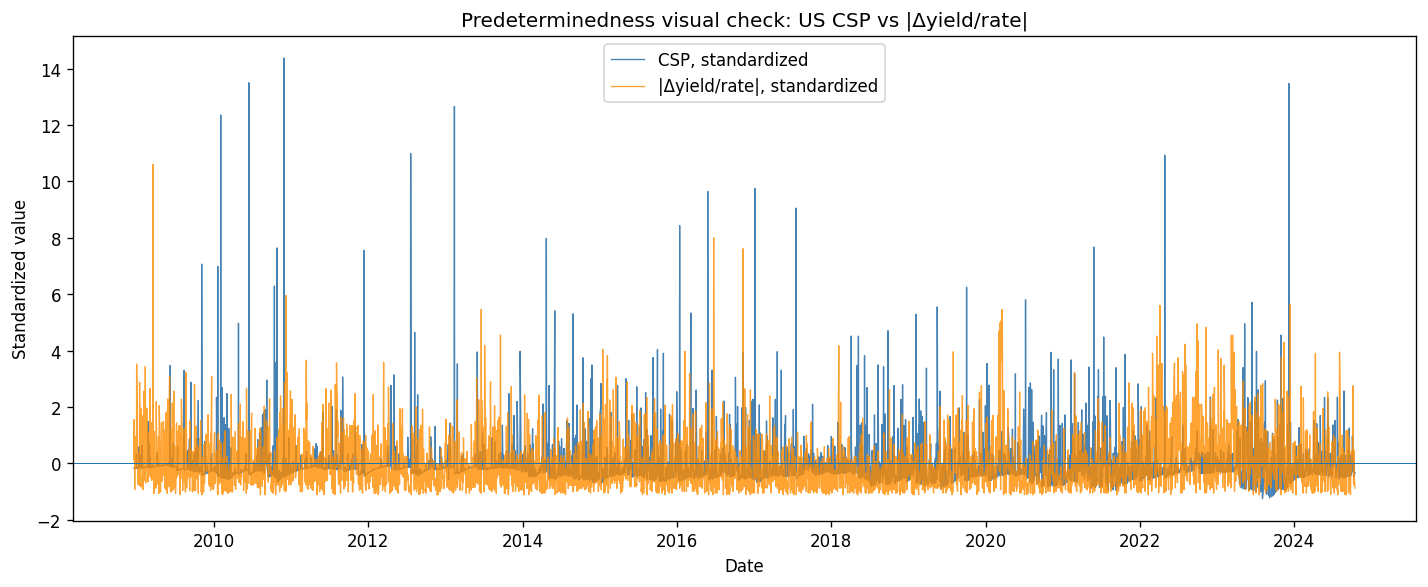

In [26]:
plot_gc = gc_df[["date", "CSP", "abs_dy"]].dropna().copy()
plot_gc["CSP_z"]    = ((plot_gc["CSP"] - plot_gc["CSP"].mean())
                        / plot_gc["CSP"].std(ddof=1))
plot_gc["abs_dy_z"] = ((plot_gc["abs_dy"] - plot_gc["abs_dy"].mean())
                        / plot_gc["abs_dy"].std(ddof=1))

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(plot_gc["date"], plot_gc["CSP_z"],
        label="CSP, standardized", lw=0.8, color="steelblue")
ax.plot(plot_gc["date"], plot_gc["abs_dy_z"],
        label="|Δyield/rate|, standardized",
        lw=0.8, alpha=0.8, color="darkorange")
ax.axhline(0, linewidth=0.6)
ax.set_title(
    f"Predeterminedness visual check: {country} CSP vs |Δyield/rate|")
ax.set_xlabel("Date")
ax.set_ylabel("Standardized value")
ax.legend()
fig.tight_layout()
fig.savefig(figdir / "predeterminedness_visual.png", dpi=130)
plt.show()

### Summary Table

In [27]:
any_granger_reject    = granger_summary["reject_H0_5pct"].any()
granger_lags_rejected = granger_summary.loc[
    granger_summary["reject_H0_5pct"], "lag"].tolist()

# Guard: f_stat and f_p may not be defined if Wald test failed
try:
    f_stat
    f_p
    wald_result      = f"F = {f_stat:.3f}, p = {f_p:.4f}"
    wald_pass        = f_p > 0.05
    wald_interp      = ("Joint null not rejected — supports predeterminedness"
                        if f_p > 0.05 else "Joint null rejected")
except NameError:
    wald_result  = "Wald test not computed — run Cell 5 first"
    wald_pass    = None
    wald_interp  = "N/A"

# Guard: obs_dc and p_dc may not be defined if Cell 6 failed
try:
    obs_dc
    p_dc
    dcor_abs_result = f"dcor = {obs_dc:.4f}, p = {p_dc:.4f}"
    dcor_abs_pass   = p_dc > 0.05
    dcor_abs_interp = ("No nonlinear dependence detected"
                       if p_dc > 0.05 else "Nonlinear dependence detected")
except NameError:
    dcor_abs_result = "Distance correlation not computed — run Cell 6 first"
    dcor_abs_pass   = None
    dcor_abs_interp = "N/A"

# Guard: k_table lookup 
try:
    dcor_dy_val    = k_table.loc[
        k_table["pair"] == "CSP vs Δyield", "dcor"].values[0]
    dcor_dy_note   = k_table.loc[
        k_table["pair"] == "CSP vs Δyield", "note"].values[0]
    dcor_dy_pass   = float(dcor_dy_val) < 0.15
except (IndexError, NameError):
    dcor_dy_val    = "N/A"
    dcor_dy_note   = "k_table not in scope — run Cell 6 first"
    dcor_dy_pass   = None

pred_summary = pd.DataFrame([
    {
        "test":            "Granger causality (|Δy| → CSP)",
        "result":          (f"Rejects H0 at lags: {granger_lags_rejected}"
                            if any_granger_reject
                            else "Fails to reject H0 at all lags"),
        "supports_predet": not any_granger_reject,
        "interpretation":  ("No evidence that past yield changes predict CSP"
                            if not any_granger_reject
                            else "Some predictability — check PACF for artefact"),
    },
    {
        "test":            "Joint Wald F-test (lags 1,2,5)",
        "result":          wald_result,
        "supports_predet": wald_pass,
        "interpretation":  wald_interp,
    },
    {
        "test":            "Distance correlation: CSP vs |Δy|",
        "result":          dcor_abs_result,
        "supports_predet": dcor_abs_pass,
        "interpretation":  dcor_abs_interp,
    },
    {
        "test":            "Distance correlation: CSP vs Δy",
        "result":          str(dcor_dy_val),
        "supports_predet": dcor_dy_pass,
        "interpretation":  dcor_dy_note,
    },
])

print("── Predeterminedness summary ──")
display(pred_summary)

valid_results = pred_summary["supports_predet"].dropna()
all_pass      = valid_results.all() if len(valid_results) > 0 else False
print(f"\nOverall: {'✓ All predeterminedness checks pass' if all_pass else '⚠ At least one check flags a concern — review individually'}")

── Predeterminedness summary ──


,test,result,supports_predet,interpretation
0,Granger causality (|Δy| → CSP),Rejects H0 at lags: [5],False,Some predictability — check PACF for artefact
1,"Joint Wald F-test (lags 1,2,5)","F = 1.058, p = 0.3655",True,Joint null not rejected — supports predetermin...
2,Distance correlation: CSP vs |Δy|,"dcor = 0.0302, p = 0.3430",True,No nonlinear dependence detected
3,Distance correlation: CSP vs Δy,0.0273,True,dcor < 0.15 supports independence



Overall: ⚠ At least one check flags a concern — review individually
